# CNN Feature Visualization, Parameter Audit & Critical Analysis
*Evaluating Convolution Kernels, Non-Linear Activations, Pooling Operations, and Architectural Trade-offs*

| Field | Details |
| :--- | :--- |
| **Student Name** | *(Enter Name)* |
| **Registration / Roll No.** | *(Enter Roll No.)* |
| **Course / Section** | Introduction to Computer Vision — Lab 12 |
| **Submission Date** | *(Enter Date)* |


## Part I: Filter Pipeline Implementation & Visualization (20%)

We extract **Figure 2** (high-contrast brutalist architectural facade with crisp horizontal floor slabs, vertical columns/mullions, and recessed dark windows) directly from the assignment PDF as a grayscale `float32` image in `[0, 255]`, resized cleanly by an exact factor of $4\times$ (`1376×768` $\to$ `344×192`, i.e., shape `(192, 344)`) so $3\times 3$ spatial kernels and $2\times 2$ pooling differences are clearly resolved. A deterministic geometric facade fallback is included so the notebook runs self-contained even without the PDF.

### Custom $3\times 3$ Convolution Kernels (`float32`)
1. **Horizontal Edge (`Sobel dI/dy`)**: $[[-1,-2,-1],[0,0,0],[1,2,1]]$ — computes the vertical gradient $\partial I/\partial y$ to detect **horizontal** structural edges. *(Naming note: the prompt lists "Horizontal Edge (Sobel-X)" / "Vertical Edge (Sobel-Y)"; in image processing, horizontal edges respond to the vertical derivative $\partial I/\partial y$ and vertical edges to $\partial I/\partial x$. Here each kernel is matched to its true edge orientation.)*
2. **Vertical Edge (`Sobel dI/dx`)**: $[[-1,0,1],[-2,0,2],[-1,0,1]]$ — computes the horizontal gradient $\partial I/\partial x$ to detect **vertical** structural edges.
3. **Sharpen**: $[[0,-1,0],[-1,5,-1],[0,-1,0]]$ — boosts high-frequency edges ($I - \nabla^2 I$).
4. **Gaussian Blur**: $\frac{1}{16}[[1,2,1],[2,4,2],[1,2,1]]$ — smooth low-pass filter (weighted analog of the $\frac{1}{9}$ uniform Box Blur, with less ringing).
5. **Emboss**: $[[-2,-1,0],[-1,1,1],[0,1,2]]$ — directional diagonal relief filter with unit DC gain ($\sum K = 1$).

Each filter passes through four sequential `float32` stages (using `replicate` padding for `'same'` output size without artificial zero-border spikes, and **never** clipping Stage A to `uint8`):
- **Stage A**: Raw signed convolution output
- **Stage B**: Post-ReLU activation, $\text{ReLU}(x) = \max(0, x)$
- **Stage C**: $2\times 2$ stride-2 Max Pooling on Stage B
- **Stage D**: $2\times 2$ stride-2 Average Pooling on Stage B


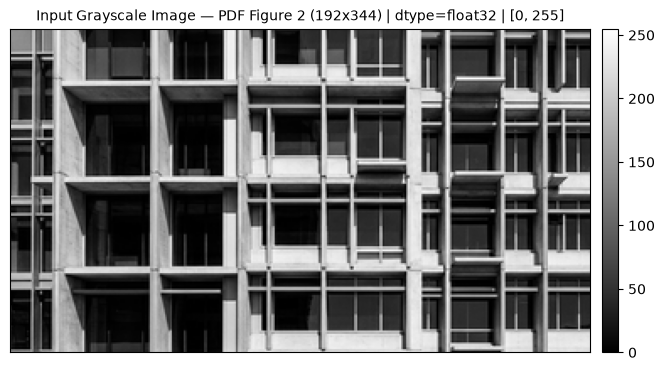

Filter                        |   A_min   A_max   A%<0 |   B_max  B%==0 |   C_max C_mean |   D_max D_mean | D/C max D/C mean
----------------------------------------------------------------------------------------------------------------------------
Horizontal Edge (Sobel dI/dy) |  -883.0  1004.0  40.6% |  1004.0  43.5% |  1004.0   75.0 |   778.2   47.6 |   77.5%    63.5%
Vertical Edge (Sobel dI/dx)   |  -938.0   977.0  49.9% |   977.0  53.0% |   977.0   88.6 |   778.8   56.4 |   79.7%    63.7%
Sharpen                       |  -353.0   679.0  20.8% |   679.0  21.9% |   679.0  152.6 |   378.0  104.1 |   55.7%    68.2%
Gaussian Blur (1/16)          |     0.0   242.4   0.0% |   242.4   0.1% |   242.4  104.6 |   241.8   93.2 |   99.7%    89.0%
Emboss                        |  -680.0   884.0  27.6% |   884.0  28.3% |   884.0  188.3 |   737.5  137.0 |   83.4%    72.8%


In [1]:
import io
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from PIL import Image


def load_architectural_image(
    pdf_name: str = "Deep Learning Lab Assignment - CNN Visualization & Critical Analysis.pdf",
    size_wh: tuple[int, int] = (344, 192),
) -> tuple[np.ndarray, str]:
    """Load Figure 2 from the lab PDF as float32 grayscale [0, 255]; fall back to synthetic facade."""
    pdf_path = Path(pdf_name)
    if pdf_path.exists():
        try:
            from pypdf import PdfReader
            raw = PdfReader(str(pdf_path)).pages[0].images[1].data
            pil = Image.open(io.BytesIO(raw)).convert("L").resize(size_wh, Image.Resampling.LANCZOS)
            return np.asarray(pil, dtype=np.float32), f"PDF Figure 2 ({size_wh[1]}x{size_wh[0]})"
        except Exception:
            pass
    # Deterministic geometric architectural facade fallback if PDF is absent
    w, h = size_wh
    img = np.linspace(195.0, 235.0, w, dtype=np.float32)[None, :].repeat(h, axis=0)
    for y0 in range(16, h - 16, 44):
        for x0 in range(18, w - 28, 54):
            img[y0:y0 + 30, x0:x0 + 38] = 20.0
            img[y0 + 26:y0 + 30, x0:x0 + 38] = 85.0  # recessed sill gradient
    img[::44, :] = 248.0  # crisp horizontal slab edges
    img[:, ::54] = 245.0  # crisp vertical column edges
    return img, f"Synthetic Architectural Facade ({h}x{w})"


img, img_source = load_architectural_image()

# Show input reference image
fig_in, ax_in = plt.subplots(figsize=(6.8, 3.6), constrained_layout=True)
im_in = ax_in.imshow(img, cmap="gray", vmin=0, vmax=255)
ax_in.set_title(f"Input Grayscale Image — {img_source} | dtype={img.dtype} | [{img.min():.0f}, {img.max():.0f}]", fontsize=10)
ax_in.set_xticks([])
ax_in.set_yticks([])
fig_in.colorbar(im_in, ax=ax_in, fraction=0.04, pad=0.02)
plt.show()

# 5 custom 3x3 float32 kernels
KERNELS = {
    "Horizontal Edge\n(Sobel dI/dy)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32),
    "Vertical Edge\n(Sobel dI/dx)":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32),
    "Sharpen":                         np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32),
    "Gaussian Blur\n(1/16)":          np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32) / 16.0,
    "Emboss":                          np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=np.float32),
}

# Replicate padding preserves exact spatial shape without artificial zero-border spikes
x = torch.from_numpy(img)[None, None]
x_pad = F.pad(x, (1, 1, 1, 1), mode="replicate")

stages = {}
header = (
    f"{'Filter':<29} | {'A_min':>7} {'A_max':>7} {'A%<0':>6} | "
    f"{'B_max':>7} {'B%==0':>6} | {'C_max':>7} {'C_mean':>6} | "
    f"{'D_max':>7} {'D_mean':>6} | {'D/C max':>7} {'D/C mean':>8}"
)
print(header)
print("-" * len(header))

for name, k in KERNELS.items():
    w = torch.from_numpy(k)[None, None]
    a = F.conv2d(x_pad, w)
    b = F.relu(a)
    c = F.max_pool2d(b, kernel_size=2, stride=2)
    d = F.avg_pool2d(b, kernel_size=2, stride=2)
    A, B, C, D = [t[0, 0].numpy() for t in (a, b, c, d)]
    stages[name] = (A, B, C, D)

    # Self-checks on shapes, dtype, sign preservation, and pooling dominance
    assert A.dtype == np.float32 and A.shape == img.shape and B.shape == img.shape
    assert C.shape == (img.shape[0] // 2, img.shape[1] // 2) and D.shape == C.shape
    assert B.min() >= 0.0 and np.all(C >= D - 1e-5)

    label = name.replace("\n", " ")
    print(
        f"{label:<29} | {A.min():7.1f} {A.max():7.1f} {(A < 0).mean() * 100:5.1f}% | "
        f"{B.max():7.1f} {(B == 0).mean() * 100:5.1f}% | {C.max():7.1f} {C.mean():6.1f} | "
        f"{D.max():7.1f} {D.mean():6.1f} | {D.max() / C.max() * 100:6.1f}% {D.mean() / C.mean() * 100:7.1f}%"
    )


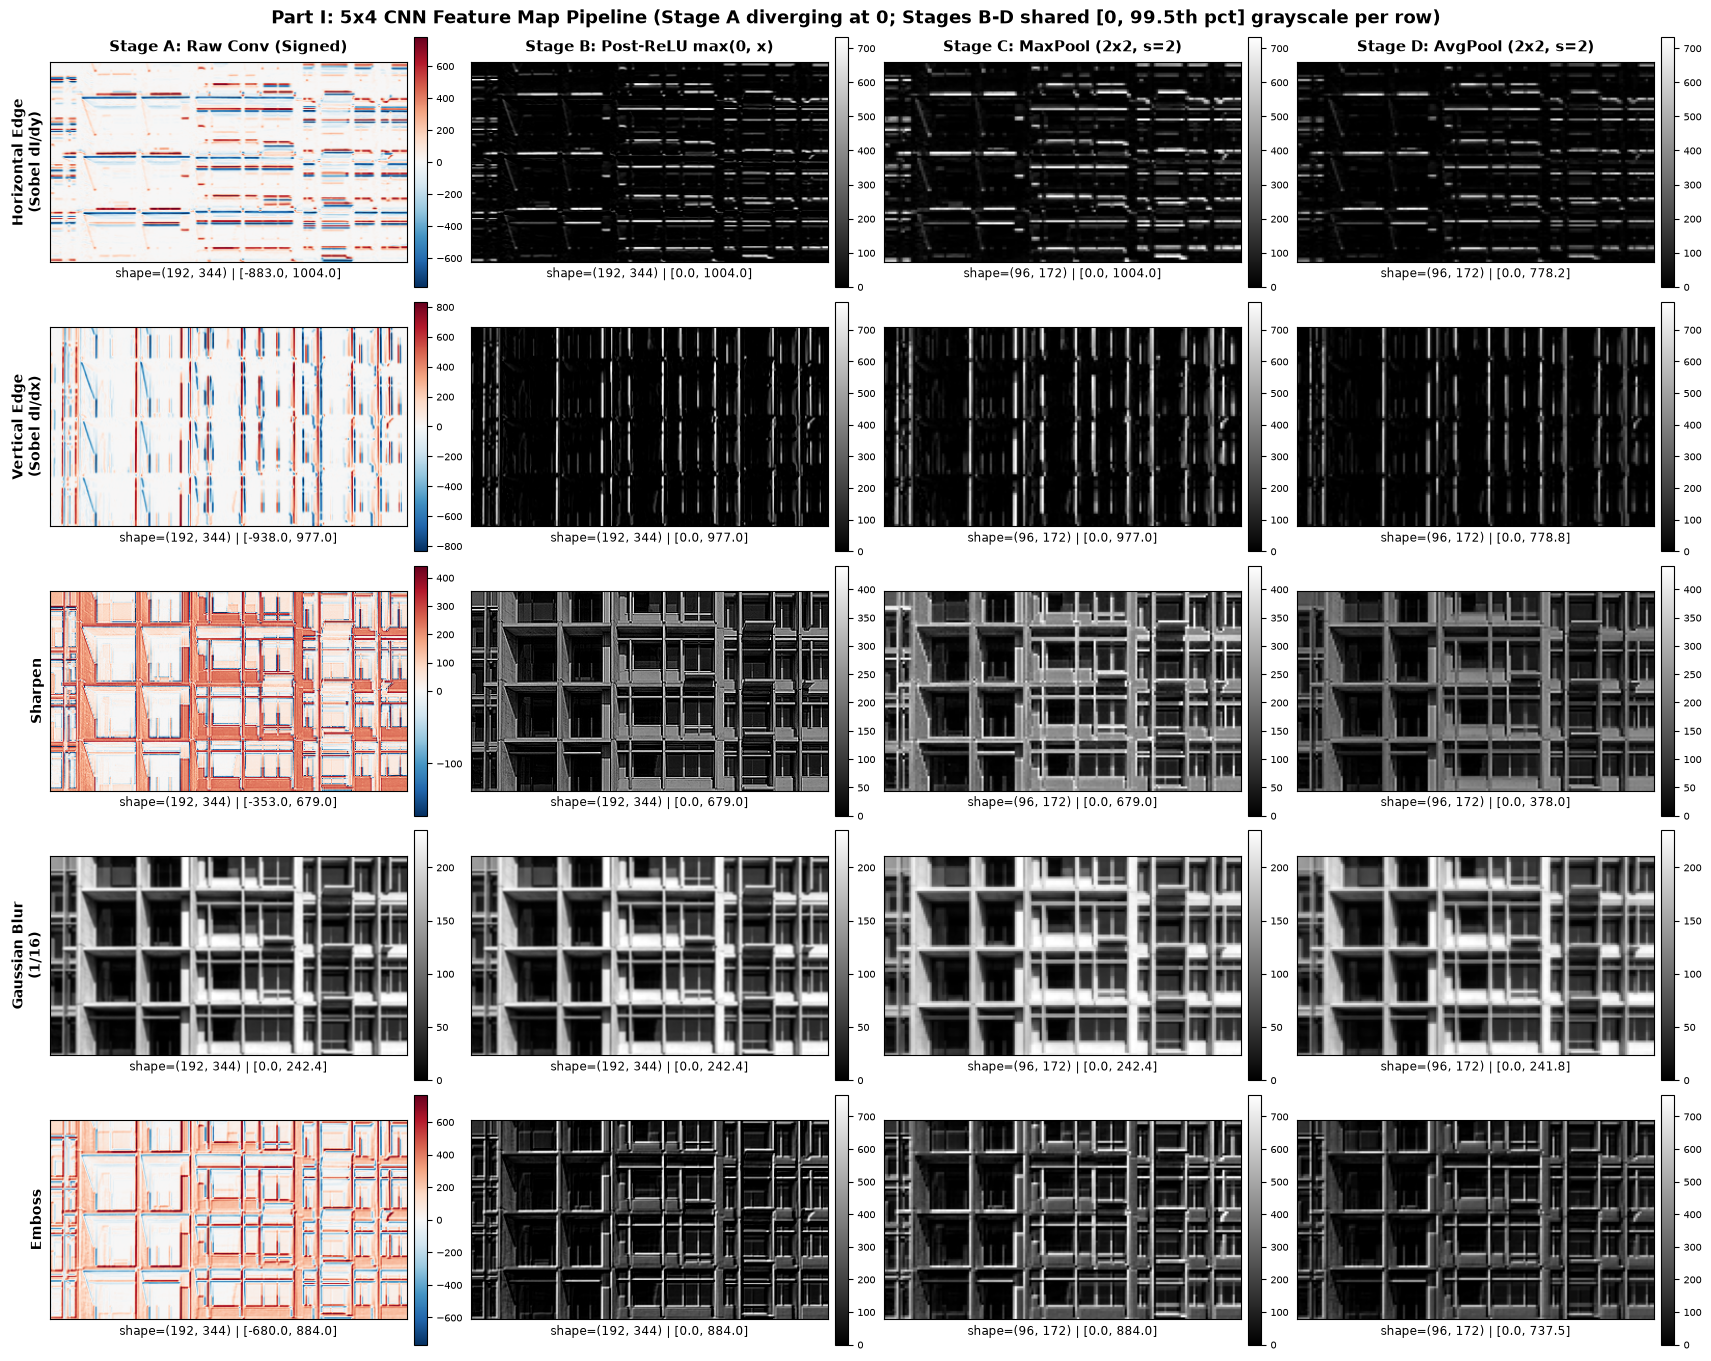

In [2]:
col_titles = [
    "Stage A: Raw Conv (Signed)",
    "Stage B: Post-ReLU max(0, x)",
    "Stage C: MaxPool (2x2, s=2)",
    "Stage D: AvgPool (2x2, s=2)",
]

fig, axes = plt.subplots(5, 4, figsize=(17, 13.5), constrained_layout=True)

for i, (name, (A, B, C, D)) in enumerate(stages.items()):
    # Shared [0, pos_vmax] scale across Stages B, C, D per row makes MaxPool vs AvgPool directly comparable
    pos_vmax = max(float(np.percentile(B, 99.5)), 1.0)
    for j, (arr, ctitle) in enumerate(zip((A, B, C, D), col_titles)):
        ax = axes[i, j]
        if j == 0 and arr.min() < 0:
            if "Sharpen" in name:
                neg_lim = min(float(np.percentile(arr, 0.5)), -1.0)
                im = ax.imshow(arr, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=neg_lim, vcenter=0.0, vmax=pos_vmax))
            else:
                sym = max(float(np.percentile(np.abs(arr), 99.5)), 1.0)
                im = ax.imshow(arr, cmap="RdBu_r", vmin=-sym, vmax=sym)
        else:
            im = ax.imshow(arr, cmap="gray", vmin=0.0, vmax=pos_vmax)

        if i == 0:
            ax.set_title(ctitle, fontsize=11, fontweight="bold", pad=8)
        if j == 0:
            ax.set_ylabel(name, fontsize=10, fontweight="bold")
        ax.set_xlabel(f"shape={arr.shape} | [{arr.min():.1f}, {arr.max():.1f}]", fontsize=8.5)
        ax.set_xticks([])
        ax.set_yticks([])
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
        cb.ax.tick_params(labelsize=7.5)

fig.suptitle(
    "Part I: 5x4 CNN Feature Map Pipeline (Stage A diverging at 0; Stages B-D shared [0, 99.5th pct] grayscale per row)",
    fontsize=13,
    fontweight="bold",
)
plt.show()


## Part II: Architectural Comparison & Parameter Audit (25%)

Both lightweight CNNs process a $32 \times 32 \times 3$ RGB input through two convolutional blocks (`Conv1: 5 filters`, `Pool1: 2×2 s=2`, `Conv2: 10 filters`, `Pool2: 2×2 s=2`), followed by `GlobalAveragePooling` and a 10-class `Dense` output layer.

### Parameter Formulas
$$\text{Params}_{\text{Conv}} = (K_h \times K_w \times C_{\text{in}} + 1) \times C_{\text{out}}, \qquad \text{Params}_{\text{Dense}} = (C_{\text{in}} + 1) \times C_{\text{out}}, \qquad \text{Params}_{\text{Pool}} = 0$$

### Step-by-Step Hand Calculations

**Model A (Standard — $3\times 3$ Kernels, Max Pooling)**
1. **Conv1** ($K=3\times 3,\; C_{\text{in}}=3,\; C_{\text{out}}=5$): $(3 \times 3 \times 3 + 1) \times 5 = 28 \times 5 = \mathbf{140}$
2. **MaxPool1** ($2\times 2$, stride 2): $\mathbf{0}$
3. **Conv2** ($K=3\times 3,\; C_{\text{in}}=5,\; C_{\text{out}}=10$): $(3 \times 3 \times 5 + 1) \times 10 = 46 \times 10 = \mathbf{460}$
4. **MaxPool2** ($2\times 2$, stride 2): $\mathbf{0}$
5. **GlobalAvgPool**: $\mathbf{0}$ (reduces $10 \times 8 \times 8 \to 10$)
6. **Dense (10)** ($C_{\text{in}}=10,\; C_{\text{out}}=10$): $(10 + 1) \times 10 = \mathbf{110}$
- **Conv Subtotal**: $140 + 460 = \mathbf{600}$ | **Total Trainable Parameters**: $140 + 460 + 110 = \mathbf{710}$

**Model B (Large Kernel — $5\times 5$ Kernels, Average Pooling)**
1. **Conv1** ($K=5\times 5,\; C_{\text{in}}=3,\; C_{\text{out}}=5$): $(5 \times 5 \times 3 + 1) \times 5 = 76 \times 5 = \mathbf{380}$
2. **AvgPool1** ($2\times 2$, stride 2): $\mathbf{0}$
3. **Conv2** ($K=5\times 5,\; C_{\text{in}}=5,\; C_{\text{out}}=10$): $(5 \times 5 \times 5 + 1) \times 10 = 126 \times 10 = \mathbf{1{,}260}$
4. **AvgPool2** ($2\times 2$, stride 2): $\mathbf{0}$
5. **GlobalAvgPool**: $\mathbf{0}$ (reduces $10 \times 8 \times 8 \to 10$)
6. **Dense (10)** ($C_{\text{in}}=10,\; C_{\text{out}}=10$): $(10 + 1) \times 10 = \mathbf{110}$
- **Conv Subtotal**: $380 + 1{,}260 = \mathbf{1{,}640}$ | **Total Trainable Parameters**: $380 + 1{,}260 + 110 = \mathbf{1{,}750}$

### Parameter Audit Table

| Model Configuration | Conv Architecture | Kernel Size | Pooling Type | Manual Count (Conv / Total) | Code Output (Conv / Total) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Model A (Standard)** | Conv1: 5 filters, Conv2: 10 filters | $3 \times 3$ | Max Pooling ($2\times 2$, stride 2) | **600 / 710** | **600 / 710** |
| **Model B (Large Kernel)** | Conv1: 5 filters, Conv2: 10 filters | $5 \times 5$ | Avg Pooling ($2\times 2$, stride 2) | **1,640 / 1,750** | **1,640 / 1,750** |

### Effective Receptive Field (ERF) Progression
Using $r_\ell = r_{\ell-1} + (k_\ell - 1) \cdot j_{\ell-1}$ and jump $j_\ell = j_{\ell-1} \cdot s_\ell$ (from $r_0=1,\; j_0=1$):

| Layer | Stride ($s$) | Jump ($j$) | Model A ERF ($3\times 3$) | Model B ERF ($5\times 5$) |
| :--- | :---: | :---: | :---: | :---: |
| Input | — | 1 | $1\times 1$ | $1\times 1$ |
| Conv1 | 1 | 1 | **$3\times 3$** | **$5\times 5$** |
| Pool1 ($2\times 2$) | 2 | 2 | $4\times 4$ | $6\times 6$ |
| Conv2 | 1 | 2 | **$8\times 8$** | **$14\times 14$** |
| Pool2 ($2\times 2$) | 2 | 4 | **$10\times 10$** | **$16\times 16$** |
| GlobalAvgPool | — | — | Full $32\times 32$ | Full $32\times 32$ |


In [3]:
class LightweightCNN(nn.Module):
    def __init__(self, kernel_size: int, pool_type: str):
        super().__init__()
        pad = kernel_size // 2  # 'same' spatial padding (does not affect param count)
        pool_cls = nn.MaxPool2d if pool_type == "max" else nn.AvgPool2d
        self.conv1 = nn.Conv2d(3, 5, kernel_size=kernel_size, padding=pad)
        self.relu1 = nn.ReLU()
        self.pool1 = pool_cls(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(5, 10, kernel_size=kernel_size, padding=pad)
        self.relu2 = nn.ReLU()
        self.pool2 = pool_cls(kernel_size=2, stride=2)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()
        self.dense = nn.Linear(10, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for layer in (self.conv1, self.relu1, self.pool1, self.conv2, self.relu2, self.pool2, self.gap, self.flatten, self.dense):
            x = layer(x)
        return x


def model_summary(model: nn.Module, title: str, input_shape: tuple[int, ...] = (1, 3, 32, 32)) -> tuple[int, int]:
    rows, hooks = [], []
    for name, module in model.named_children():
        def _hook(mod, _inp, out, n=name):
            params = sum(p.numel() for p in mod.parameters() if p.requires_grad)
            rows.append((n, mod.__class__.__name__, tuple(out.shape), params))
        hooks.append(module.register_forward_hook(_hook))

    with torch.no_grad():
        out = model(torch.randn(*input_shape))
    for h in hooks:
        h.remove()

    print(f"=== {title} (PyTorch {torch.__version__}) ===")
    print(f"{'Layer':<12} {'Type':<18} {'Output Shape':<18} {'Trainable Params':>16}")
    print("-" * 68)
    for n, t, s, p in rows:
        print(f"{n:<12} {t:<18} {str(s):<18} {p:>16,}")
    conv_params = sum(p for n, _, _, p in rows if n.startswith("conv"))
    total_params = sum(p for _, _, _, p in rows)
    print("-" * 68)
    print(f"{'Conv Subtotal':<50} {conv_params:>16,}")
    print(f"{'Total Trainable Parameters':<50} {total_params:>16,}\n")
    assert out.shape == (1, 10)
    return conv_params, total_params


model_a = LightweightCNN(kernel_size=3, pool_type="max")
model_b = LightweightCNN(kernel_size=5, pool_type="avg")

conv_a, total_a = model_summary(model_a, "Model A (Standard: 3x3 Conv + MaxPool)")
conv_b, total_b = model_summary(model_b, "Model B (Large Kernel: 5x5 Conv + AvgPool)")

assert (conv_a, total_a) == (600, 710), f"Unexpected Model A counts: {(conv_a, total_a)}"
assert (conv_b, total_b) == (1640, 1750), f"Unexpected Model B counts: {(conv_b, total_b)}"
print("Verified: PyTorch summaries match manual hand calculations exactly (710 and 1,750).")


=== Model A (Standard: 3x3 Conv + MaxPool) (PyTorch 2.14.0+cpu) ===
Layer        Type               Output Shape       Trainable Params
--------------------------------------------------------------------
conv1        Conv2d             (1, 5, 32, 32)                  140
relu1        ReLU               (1, 5, 32, 32)                    0
pool1        MaxPool2d          (1, 5, 16, 16)                    0
conv2        Conv2d             (1, 10, 16, 16)                 460
relu2        ReLU               (1, 10, 16, 16)                   0
pool2        MaxPool2d          (1, 10, 8, 8)                     0
gap          AdaptiveAvgPool2d  (1, 10, 1, 1)                     0
flatten      Flatten            (1, 10)                           0
dense        Linear             (1, 10)                         110
--------------------------------------------------------------------
Conv Subtotal                                                   600
Total Trainable Parameters                    

## Part III: Critical Thinking & Viva Defense Questions (55%)

---

### Question 1 — The ReLU "Blackout" Effect & Activation Alternatives

**Which structural regions turned pure black (`0.0`) from Stage A $\to$ Stage B, and why?**
- **Row 1 — Horizontal Edge (`Sobel dI/dy`, `[[-1,-2,-1],[0,0,0],[1,2,1]]`)**: Stage A spans `[-883.0, +1004.0]` with **40.6% negative pixels** (blue stripes); after ReLU in Stage B, **43.5% of the map collapses to pure black (`0.0`)**. Specifically, the **lower undersides of every bright horizontal concrete slab and window lintel** vanish. At those boundaries, bright sunlit concrete sits above ($\approx 200$) and dark recessed window/shadow sits below ($\approx 20$), giving a negative vertical gradient: $(-1-2-1)\cdot 200 + (1+2+1)\cdot 20 = -720 < 0$. ReLU zeroes all negative transitions, keeping only the **upper edges** of slabs and window sills (dark above $\to$ bright below, positive red stripes in Stage A).
- **Row 2 — Vertical Edge (`Sobel dI/dx`, `[[-1,0,1],[-2,0,2],[-1,0,1]]`)**: Stage A spans `[-938.0, +977.0]` with **49.9% negative pixels**; Stage B zeroes **53.0% of the map**. The **right-hand edges of bright vertical concrete columns and window mullions** (plus left-to-right diagonal shadow drops inside the balconies) turn pure black because bright concrete on the left transitions into dark window cavity on the right ($\partial I/\partial x < 0$). Only the **left-hand vertical faces** (dark $\to$ bright) survive as white lines.

**What changes visually and mathematically with Leaky ReLU ($\alpha = 0.1$) or Sigmoid?**
- **Leaky ReLU**, $f(x) = x$ for $x > 0$ else $0.1x$:
  - *Mathematically*: Negative gradients are scaled by $0.1$ instead of clamped to $0$ (e.g., `-883.0` $\to$ `-88.3`, `-938.0` $\to$ `-93.8`), maintaining a non-zero slope $f'(x) = 0.1$ everywhere in the negative half-plane so neurons cannot permanently "die."
  - *Visually*: Instead of hard blackouts, the underside horizontal edges and right-side vertical column edges remain faintly preserved as subtle negative-polarity shadows while positive edges dominate at full amplitude.
- **Sigmoid**, $\sigma(x) = \frac{1}{1 + e^{-x}} \in (0, 1)$:
  - *Mathematically*: Zero-gradient flat concrete/window regions map to $\sigma(0) = \mathbf{0.5}$ rather than $0$. Worse, raw Sobel magnitudes here are huge (hundreds of intensity units), so almost every edge pixel satisfies $|x| > 6$ and **saturates** to $\sigma(x) \approx 0$ or $1$, where the derivative $\sigma'(x) = \sigma(x)(1-\sigma(x)) \approx 0$ causes **vanishing gradients**.
  - *Visually*: Flat background turns mid-gray (`0.5`), while subtle edge-strength variations are crushed into an almost binary black-and-white outline (black for negative edges, white for positive edges).

---

### Question 2 — Max Pooling vs. Average Pooling Information Retention

**Stage C vs. Stage D across Sharpen and Edge rows (shared per-row intensity scale):**
- **Row 3 — Sharpen**: High-frequency concrete-to-window frame highlights reach **`679.0`** in Stage B and remain at **`679.0` (100% peak retention, mean `152.6`)** under MaxPool (Stage C). Under AvgPool (Stage D), the peak collapses to **`378.0` (only `55.7%` of Stage C)** and the mean drops to **`104.1` (`68.2%`)**, visibly washing out crisp window-mullion highlights.
- **Rows 1 & 2 — Horizontal & Vertical Edge**: MaxPool retains 100% of peak edge activations (`1004.0` and `977.0`, means `75.0` and `88.6`) and keeps thin 1-pixel concrete slab/column outlines bright and continuous. AvgPool dims peaks to `778.2` (**`77.5%`**) and `778.8` (**`79.7%`**) and cuts mean edge energy by **`~36%`** (`47.6` and `56.4`), because a 1-pixel bright edge line shares its $2\times 2$ window with 2–3 black (`0.0`) pixels and gets divided by 4.
- *(Contrast with **Row 4 — Gaussian Blur**: because high frequencies were already smoothed away, AvgPool retains **`99.7%`** of Stage C's peak, `241.8` vs. `242.4`.)*

**Dark ink text (`~0`) on a pure white background (`~255`) — which pooling preserves strokes better?**
- **Average Pooling** preserves dark text strokes dramatically better. Consider a $2\times 2$ patch straddling a thin dark stroke: $\begin{bmatrix}0 & 255 \\ 255 & 255\end{bmatrix}$.
  - **Max Pooling** selects $\max = \mathbf{255}$ (pure white background), **completely erasing thin strokes** and fragmenting characters.
  - **Average Pooling** outputs $\frac{0 + 255 + 255 + 255}{4} = \mathbf{191.25}$, preserving a dimmed gray trace of the stroke.
- *(Practical CV note: if you invert the image via $255 - I$ so ink is bright `~255` on a `0` background—or apply **Min Pooling**—then Max Pooling preserves the strokes cleanly without blurring.)*

---

### Question 3 — Parameter Explosion & Receptive Field Equivalence

1. **Exact percentage increase from Model A ($3\times 3$) to Model B ($5\times 5$):**
   - **Total trainable parameters** ($710 \to 1{,}750$, $+1{,}040$):
     $$\frac{1750 - 710}{710} \times 100\% = \frac{1040}{710} \times 100\% \approx \mathbf{146.48\%} \quad (2.46\times)$$
   - **Convolutional parameters only** ($600 \to 1{,}640$, $+1{,}040$, excluding the unchanged 110-param Dense head):
     $$\frac{1640 - 600}{600} \times 100\% = \frac{1040}{600} \times 100\% \approx \mathbf{173.33\%} \quad (2.73\times)$$
2. **Stacked $3\times 3$ layers for an identical $5\times 5$ receptive field:**
   - Each stride-1 $3\times 3$ layer expands the receptive field by $+2$: $r_0 = 1 \to r_1 = 3 \to r_2 = 1 + 2 + 2 = \mathbf{5}$.
   - Exactly **2 stacked $3\times 3$ convolutional layers** match a single $5\times 5$ receptive field—while adding an extra intermediate ReLU non-linearity for higher representational power (the VGGNet principle).
3. **Parameter savings:**
   - **General symmetric case ($C \to C$ channels)**:
     - Single $5\times 5$: $(25C + 1)C = 25C^2 + C$
     - Two stacked $3\times 3$ ($C \to C \to C$): $2(9C + 1)C = 18C^2 + 2C$
     - **Saved**: $(25C^2 + C) - (18C^2 + 2C) = \mathbf{7C^2 - C}$ parameters (**28%** fewer weights, $\frac{7}{25}$, positive for all $C \ge 1$).
   - **On Model B's exact layers (channel-asymmetric)**:
     - **Conv1 ($3 \to 5$)**: Single $5\times 5 = 380$. Two $3\times 3$ ($3 \to 5 \to 5$) $= 140 + 230 = 370$ (**saves 10 params / 2.63%**); deferring expansion ($3 \to 3 \to 5$) $= 84 + 140 = 224$ (**saves 156 params / 41.05%**).
     - **Conv2 ($5 \to 10$)**: Single $5\times 5 = 1{,}260$. Deferring channel expansion ($5 \to 5 \to 10$) $= 230 + 460 = 690$ (**saves 570 params / 45.24%**). *(Expanding early as $5 \to 10 \to 10$ costs $460 + 910 = 1{,}370$, $+110$, because the second layer operates at $2\times$ channel width—highlighting why bottlenecks/late expansion matter.)*

---

### Question 4 — Operation Commutativity (Order Invariance)

**Will `Conv → ReLU → MaxPool` and `Conv → MaxPool → ReLU` produce identical tensors?**
- **Yes — bit-for-bit identical.**

**Mathematical Proof:**
Because $\text{ReLU}(x) = \max(0, x)$ is monotonically non-decreasing ($a \le b \implies \max(0,a) \le \max(0,b)$) and $\max$ is associative and commutative, for any pooling window $W = \{x_1, \dots, x_k\}$:
$$\max_{i \in W}\big(\max(0, x_i)\big) = \max(0, x_1, \dots, x_k) = \max\!\left(0,\; \max_{i \in W} x_i\right)$$
Hence $\text{MaxPool}(\text{ReLU}(X)) \equiv \text{ReLU}(\text{MaxPool}(X))$. *(Note: **Average Pooling** does **not** commute with ReLU because averaging is linear while $\max(0,\cdot)$ is convex/nonlinear.)*

**Explicit $2\times 2$ Sample Patches with Negative Numbers:**
- **All-negative patch** $P_1 = \begin{bmatrix}-4 & -1 \\ -7 & -2\end{bmatrix}$:
  - `ReLU → MaxPool`: $\begin{bmatrix}0 & 0 \\ 0 & 0\end{bmatrix} \xrightarrow{\max} \mathbf{0}$
  - `MaxPool → ReLU`: $\max(P_1) = -1 \xrightarrow{\text{ReLU}} \max(0, -1) = \mathbf{0}$  (Identical)
- **Mixed-sign patch** $P_2 = \begin{bmatrix}-5 & 3 \\ -2 & -8\end{bmatrix}$:
  - `ReLU → MaxPool`: $\begin{bmatrix}0 & 3 \\ 0 & 0\end{bmatrix} \xrightarrow{\max} \mathbf{3}$
  - `MaxPool → ReLU`: $\max(P_2) = 3 \xrightarrow{\text{ReLU}} \max(0, 3) = \mathbf{3}$  (Identical; whereas `AvgPool(ReLU(P2)) = 0.75 != ReLU(AvgPool(P2)) = 0.0`)

**Computational Efficiency Implication:**
A $2\times 2$ stride-2 MaxPool shrinks spatial dimensions by $4\times$ ($H \times W \to \frac{H}{2} \times \frac{W}{2}$). Placing `MaxPool` **before** `ReLU` eliminates **75% of all ReLU element-wise comparisons and activation memory writes** while yielding the exact same output tensor.

---

### Question 5 — Diagnosing Filter Redundancy (Debugging Scenario)

When all 5 learned Layer 1 filters converge to nearly identical feature maps after 20 epochs, two distinct root causes and concrete fixes are:

1. **Symmetric / Constant Weight Initialization (Initialization Bug)**
   - *Mechanism*: Initializing all 5 filters to identical values (e.g., all zeros or the same constant) gives every filter the exact same forward activation and therefore the exact same backpropagated gradient at every training step. Gradient descent preserves this permutation symmetry indefinitely, locking all 5 filters into identical copies.
   - *Concrete Fix*: Break symmetry with variance-scaled random initialization tailored to ReLU—**He / Kaiming initialization** ($w \sim \mathcal{N}(0, 2/n_{\text{in}})$, e.g., `nn.init.kaiming_normal_(conv.weight, nonlinearity="relu")`) with zero biases.

2. **Dying ReLU Collapse Triggered by an Excessively High Learning Rate (Optimization Bug)**
   - *Mechanism*: An oversized learning rate produces a large initial gradient step that pushes filter weights/biases into the negative half-space ($z \le 0$) across almost all training images. Once $z \le 0$, $\text{ReLU}(z) = 0$ and $\frac{\partial \text{ReLU}}{\partial z} = 0$, permanently cutting off gradient updates so all affected filters collapse into identical all-zero (or trivial constant) feature maps.
   - *Concrete Fix*: Reduce the learning rate (e.g., $10\times$ smaller with warmup and gradient clipping), replace ReLU with **Leaky ReLU** ($\alpha = 0.01\text{--}0.1$) or **GELU** so negative pre-activations retain non-zero gradient flow, and insert **Batch Normalization** before the activation to keep pre-activations centered near zero with unit variance.


In [4]:
# Programmatic verification of Part III mathematical claims (Q1, Q3, Q4)

# Q1: Sigmoid saturation fraction on Horizontal Edge Stage A (|x| > 6 -> sigma'(x) < 0.0025)
A_horiz = stages["Horizontal Edge\n(Sobel dI/dy)"][0]
sig_sat_pct = (np.abs(A_horiz) > 6.0).mean() * 100
print(f"Q1 check — Horizontal Edge |Stage A| > 6 (Sigmoid saturation zone): {sig_sat_pct:.1f}% of pixels")

# Q3: Parameter increase & stacked 3x3 savings
inc_total = (total_b - total_a) / total_a * 100
inc_conv = (conv_b - conv_a) / conv_a * 100
assert abs(inc_total - 146.4788732) < 1e-4 and abs(inc_conv - 173.3333333) < 1e-4
print(f"Q3 check — Total param increase: {inc_total:.2f}% | Conv param increase: {inc_conv:.2f}%")

# Q4: MaxPool <-> ReLU commutativity on negative patches AND all 5 real Part I feature maps
for name, p in [("P1 (all-neg)", [[-4.0, -1.0], [-7.0, -2.0]]), ("P2 (mixed)", [[-5.0, 3.0], [-2.0, -8.0]])]:
    t = torch.tensor(p, dtype=torch.float32)[None, None]
    lhs = F.max_pool2d(F.relu(t), 2, stride=2).item()
    rhs = F.relu(F.max_pool2d(t, 2, stride=2)).item()
    assert lhs == rhs
    print(f"Q4 check — {name}: MaxPool(ReLU)={lhs:.1f} == ReLU(MaxPool)={rhs:.1f}")

# Confirm AvgPool does NOT commute with ReLU on P2
p2 = torch.tensor([[-5.0, 3.0], [-2.0, -8.0]], dtype=torch.float32)[None, None]
avg_lhs = F.avg_pool2d(F.relu(p2), 2, stride=2).item()
avg_rhs = F.relu(F.avg_pool2d(p2, 2, stride=2)).item()
assert avg_lhs != avg_rhs
print(f"Q4 check — AvgPool non-commutativity on P2: AvgPool(ReLU)={avg_lhs:.2f} != ReLU(AvgPool)={avg_rhs:.2f}")

# Verify bit-identical MaxPool<->ReLU commutativity across all 5 full Part I feature maps
for name, (A, _B, C, _D) in stages.items():
    alt_C = F.relu(F.max_pool2d(torch.from_numpy(A)[None, None], 2, stride=2))[0, 0].numpy()
    assert np.array_equal(C, alt_C), f"Commutativity failed on {name}"
print("Q4 check — Verified bit-identical MaxPool(ReLU(A)) == ReLU(MaxPool(A)) across all 5 filters.")


Q1 check — Horizontal Edge |Stage A| > 6 (Sigmoid saturation zone): 72.5% of pixels
Q3 check — Total param increase: 146.48% | Conv param increase: 173.33%
Q4 check — P1 (all-neg): MaxPool(ReLU)=0.0 == ReLU(MaxPool)=0.0
Q4 check — P2 (mixed): MaxPool(ReLU)=3.0 == ReLU(MaxPool)=3.0
Q4 check — AvgPool non-commutativity on P2: AvgPool(ReLU)=0.75 != ReLU(AvgPool)=0.00
Q4 check — Verified bit-identical MaxPool(ReLU(A)) == ReLU(MaxPool(A)) across all 5 filters.
